Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Google Drive output directory: /content/drive/MyDrive/Severstal_UNet_Training
Local ZIP already exists.
Dataset directory already exists.
Dataset files:
severstal/
  test_images/
  train_images/

train.csv: /content/severstal/train.csv

train_images: /content/severstal/train_images

DEVICE
cuda
GPU: NVIDIA A100-SXM4-40GB
GPU Memory: 39.49 GB

DATASET
         ImageId  ClassId                                      EncodedPixels
0  0002cc93b.jpg        1  29102 12 29346 24 29602 24 29858 24 30114 24 3...
1  0007a71bf.jpg        3  18661 28 18863 82 19091 110 19347 110 19603 11...
2  000a4bcdd.jpg        1  37607 3 37858 8 38108 14 38359 20 38610 25 388...
3  000f6bf48.jpg        4  131973 1 132228 4 132483 6 132738 8 132993 11 ...
4  0014fce06.jpg        3  229501 11 229741 33 229981 55 230221 77 230468...

Shape: (7095, 3)

Class distribution:
ClassId
1     897

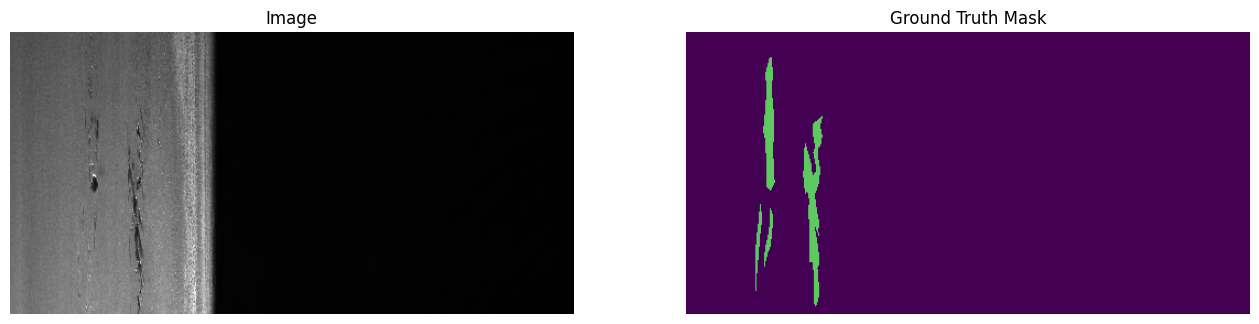


MODEL
Total parameters: 7,763,173
Trainable parameters: 7,763,173

Input: torch.Size([2, 3, 256, 512])
Output: torch.Size([2, 5, 256, 512])
Forward pass: OK

PIXEL FREQUENCY
Class 1: 3,912,129
Class 2: 834,471
Class 3: 131,306,899
Class 4: 27,533,572

LOSS WEIGHTS
Class 0: 0.2500
Class 1: 1.5170
Class 2: 1.5170
Class 3: 0.3034
Class 4: 0.6626


/tmp/ipykernel_846/3454832052.py:411: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/tmp/ipykernel_846/3454832052.py:444: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=use_amp):



No previous checkpoint found.
Starting training from epoch 1.

TRAINING STARTED


/tmp/ipykernel_846/3454832052.py:464: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=use_amp):



Epoch [1/40]
Train Loss : 0.58171
Val Loss   : 0.47750
Mean Dice  : 0.13818
Mean IoU   : 0.09514
LR         : 0.00100000
Time       : 122.0 sec

Class Dice:
  Class 1: 0.00000
  Class 2: 0.00000
  Class 3: 0.54974
  Class 4: 0.00297

Class IoU:
  Class 1: 0.00000
  Class 2: 0.00000
  Class 3: 0.37906
  Class 4: 0.00149

🔥 NEW BEST MODEL SAVED TO GOOGLE DRIVE
Best Dice = 0.13818

💾 Last checkpoint saved to Google Drive.

Epoch [2/40]
Train Loss : 0.43367
Val Loss   : 0.42645
Mean Dice  : 0.25634
Mean IoU   : 0.17252
LR         : 0.00100000
Time       : 28.7 sec

Class Dice:
  Class 1: 0.00000
  Class 2: 0.00000
  Class 3: 0.53626
  Class 4: 0.48909

Class IoU:
  Class 1: 0.00000
  Class 2: 0.00000
  Class 3: 0.36636
  Class 4: 0.32371

🔥 NEW BEST MODEL SAVED TO GOOGLE DRIVE
Best Dice = 0.25634

💾 Last checkpoint saved to Google Drive.

Epoch [3/40]
Train Loss : 0.39813
Val Loss   : 0.37058
Mean Dice  : 0.31247
Mean IoU   : 0.21551
LR         : 0.00100000
Time       : 28.6 sec

Class Di

UnpicklingError: Weights only load failed. This file can still be loaded, to do so you have two options, [1mdo those steps only if you trust the source of the checkpoint[0m. 
	(1) In PyTorch 2.6, we changed the default value of the `weights_only` argument in `torch.load` from `False` to `True`. Re-running `torch.load` with `weights_only` set to `False` will likely succeed, but it can result in arbitrary code execution. Do it only if you got the file from a trusted source.
	(2) Alternatively, to load with `weights_only=True` please check the recommended steps in the following error message.
	WeightsUnpickler error: Unsupported global: GLOBAL numpy._core.multiarray._reconstruct was not an allowed global by default. Please use `torch.serialization.add_safe_globals([numpy._core.multiarray._reconstruct])` or the `torch.serialization.safe_globals([numpy._core.multiarray._reconstruct])` context manager to allowlist this global if you trust this class/function.

Check the documentation of to

In [ ]:
# ============================================================
# SEVERSTAL STEEL DEFECT SEGMENTATION
# Complete U-Net Training Pipeline
# ============================================================

# 1. INSTALL PACKAGES
!pip install -q albumentations

# 2. IMPORTS
import os
import random
import shutil
import zipfile
import time
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import albumentations as A
from google.colab import drive

# 3. MOUNT GOOGLE DRIVE
drive.mount("/content/drive")

# 4. PATHS
DRIVE_ZIP = "/content/drive/MyDrive/severstal-steel-defect-detection.zip"
LOCAL_ZIP = "/content/severstal-steel-defect-detection.zip"
DATASET_DIR = "/content/severstal"
DRIVE_OUTPUT_DIR = "/content/drive/MyDrive/Severstal_UNet_Training"
CHECKPOINT_DIR = os.path.join(DRIVE_OUTPUT_DIR, "checkpoints")
RESULTS_DIR = os.path.join(DRIVE_OUTPUT_DIR, "results")
os.makedirs(DRIVE_OUTPUT_DIR, exist_ok=True)
os.makedirs(CHECKPOINT_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)
print("Google Drive output directory:", DRIVE_OUTPUT_DIR)

# 5. COPY ZIP FROM DRIVE TO LOCAL TEMPORARY STORAGE
if not os.path.exists(LOCAL_ZIP):
    print("Copying ZIP from Google Drive...")
    shutil.copy(DRIVE_ZIP, LOCAL_ZIP)
    print("ZIP copied.")
else:
    print("Local ZIP already exists.")

# 6. EXTRACT DATASET
if not os.path.exists(DATASET_DIR):
    print("Extracting dataset...")
    shutil.unpack_archive(LOCAL_ZIP, DATASET_DIR)
    print("Dataset extracted.")
else:
    print("Dataset directory already exists.")

print("Dataset files:")
for root, dirs, files in os.walk(DATASET_DIR):
    level = root.replace(DATASET_DIR, "").count(os.sep)
    indent = " " * 2 * level
    print(indent + os.path.basename(root) + "/")
    if level >= 2:
        dirs[:] = []

# 7. FIND DATASET PATHS
TRAIN_CSV = os.path.join(DATASET_DIR, "train.csv")
TRAIN_IMAGE_DIR = os.path.join(DATASET_DIR, "train_images")
if not os.path.exists(TRAIN_CSV):
    for root, dirs, files in os.walk(DATASET_DIR):
        if "train.csv" in files:
            TRAIN_CSV = os.path.join(root, "train.csv")
            break
if not os.path.exists(TRAIN_IMAGE_DIR):
    for root, dirs, files in os.walk(DATASET_DIR):
        if os.path.basename(root) == "train_images":
            TRAIN_IMAGE_DIR = root
            break
print()
print("train.csv:", TRAIN_CSV)
print()
print("train_images:", TRAIN_IMAGE_DIR)
assert os.path.exists(TRAIN_CSV), "train.csv not found!"
assert os.path.exists(TRAIN_IMAGE_DIR), "train_images directory not found!"

# 8. CONFIGURATION
SEED = 42
NUM_CLASSES = 5
IMAGE_HEIGHT = 256
IMAGE_WIDTH = 512
BATCH_SIZE = 16
NUM_EPOCHS = 40
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
NUM_WORKERS = 4
VAL_SIZE = 0.20
EARLY_STOPPING_PATIENCE = 8
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print()
print("==============================")
print("DEVICE")
print("==============================")
print(DEVICE)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU Memory:", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2), "GB")

# 9. SEED
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = True
set_seed(SEED)

# 10. LOAD TRAIN.CSV
df = pd.read_csv(TRAIN_CSV)
print()
print("==============================")
print("DATASET")
print("==============================")
print(df.head())
print()
print("Shape:", df.shape)
print()
print("Class distribution:")
print(df["ClassId"].value_counts().sort_index())

# 11. RLE DECODER
def rle_decode(rle, shape=(256, 1600)):
    mask = np.zeros(shape[0] * shape[1], dtype=np.uint8)
    if pd.isna(rle):
        return mask.reshape(shape, order="F")
    values = np.asarray(rle.split(), dtype=np.int64)
    starts = values[0::2] - 1
    lengths = values[1::2]
    ends = starts + lengths
    for start, end in zip(starts, ends):
        mask[start:end] = 1
    return mask.reshape(shape, order="F")

# 12. UNIQUE IMAGE IDs
image_ids = df["ImageId"].unique().tolist()
print()
print("Unique defective images:", len(image_ids))

# 13. TRAIN / VALIDATION SPLIT
train_ids, val_ids = train_test_split(image_ids, test_size=VAL_SIZE, random_state=SEED, shuffle=True)
train_ids = list(train_ids)
val_ids = list(val_ids)
print()
print("==============================")
print("SPLIT")
print("==============================")
print("Train images:", len(train_ids))
print("Validation images:", len(val_ids))

# 14. AUGMENTATION
train_transform = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.RandomBrightnessContrast(brightness_limit=0.15, contrast_limit=0.15, p=0.3),
])
val_transform = None

# 15. DATASET
class SteelDefectDataset(Dataset):
    def __init__(self, image_ids, df, image_dir, transform=None):
        self.image_ids = list(image_ids)
        self.df = df
        self.image_dir = image_dir
        self.transform = transform
        self.annotations = {image_id: group for image_id, group in df.groupby("ImageId")}
    def __len__(self):
        return len(self.image_ids)
    def __getitem__(self, idx):
        image_id = self.image_ids[idx]
        image_path = os.path.join(self.image_dir, image_id)
        image = cv2.imread(image_path)
        if image is None:
            raise FileNotFoundError(f"Image not found: {image_path}")
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        mask = np.zeros((256, 1600), dtype=np.uint8)
        if image_id in self.annotations:
            rows = self.annotations[image_id]
            for _, row in rows.iterrows():
                class_id = int(row["ClassId"])
                class_mask = rle_decode(row["EncodedPixels"], shape=(256, 1600))
                mask[class_mask == 1] = class_id
        if self.transform is not None:
            augmented = self.transform(image=image, mask=mask)
            image = augmented["image"]
            mask = augmented["mask"]
        image = cv2.resize(image, (IMAGE_WIDTH, IMAGE_HEIGHT), interpolation=cv2.INTER_LINEAR)
        mask = cv2.resize(mask, (IMAGE_WIDTH, IMAGE_HEIGHT), interpolation=cv2.INTER_NEAREST)
        image = image.astype(np.float32) / 255.0
        image = torch.from_numpy(image).permute(2, 0, 1)
        mask = torch.from_numpy(mask).long()
        return image, mask

# 16. CREATE DATASETS
train_dataset = SteelDefectDataset(image_ids=train_ids, df=df, image_dir=TRAIN_IMAGE_DIR, transform=train_transform)
val_dataset = SteelDefectDataset(image_ids=val_ids, df=df, image_dir=TRAIN_IMAGE_DIR, transform=val_transform)
print()
print("Train dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))

# 17. DATALOADER
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=True, persistent_workers=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True, persistent_workers=True)

# 18. CHECK DATA
images, masks = next(iter(train_loader))
print()
print("==============================")
print("DATALOADER CHECK")
print("==============================")
print("Images:", images.shape)
print("Masks:", masks.shape)
print("Image dtype:", images.dtype)
print("Mask dtype:", masks.dtype)
print("Mask classes:", torch.unique(masks))

# 19. VISUALIZE DATA
def show_sample(dataset, index):
    image, mask = dataset[index]
    image_np = image.permute(1, 2, 0).numpy()
    mask_np = mask.numpy()
    plt.figure(figsize=(16, 5))
    plt.subplot(1, 2, 1)
    plt.imshow(image_np)
    plt.title("Image")
    plt.axis("off")
    plt.subplot(1, 2, 2)
    plt.imshow(mask_np, vmin=0, vmax=4)
    plt.title("Ground Truth Mask")
    plt.axis("off")
    plt.show()
for i in range(len(train_dataset)):
    _, mask = train_dataset[i]
    if torch.any(mask > 0):
        show_sample(train_dataset, i)
        break

# 20. U-NET - DOUBLE CONV
class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )
    def forward(self, x):
        return self.block(x)

# 21. U-NET DOWN BLOCK
class DownBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.pool = nn.MaxPool2d(kernel_size=2)
        self.conv = DoubleConv(in_channels, out_channels)
    def forward(self, x):
        x = self.pool(x)
        x = self.conv(x)
        return x

# 22. U-NET UP BLOCK
class UpBlock(nn.Module):
    def __init__(self, in_channels, skip_channels, out_channels):
        super().__init__()
        self.up = nn.ConvTranspose2d(in_channels, in_channels // 2, kernel_size=2, stride=2)
        self.conv = DoubleConv(in_channels // 2 + skip_channels, out_channels)
    def forward(self, x, skip):
        x = self.up(x)
        diff_y = skip.size(2) - x.size(2)
        diff_x = skip.size(3) - x.size(3)
        x = F.pad(x, [diff_x // 2, diff_x - diff_x // 2, diff_y // 2, diff_y - diff_y // 2])
        x = torch.cat([skip, x], dim=1)
        x = self.conv(x)
        return x

# 23. U-NET
class UNet(nn.Module):
    def __init__(self, in_channels=3, num_classes=5, base_channels=32):
        super().__init__()
        self.inc = DoubleConv(in_channels, base_channels)
        self.down1 = DownBlock(base_channels, base_channels * 2)
        self.down2 = DownBlock(base_channels * 2, base_channels * 4)
        self.down3 = DownBlock(base_channels * 4, base_channels * 8)
        self.down4 = DownBlock(base_channels * 8, base_channels * 16)
        self.up1 = UpBlock(base_channels * 16, base_channels * 8, base_channels * 8)
        self.up2 = UpBlock(base_channels * 8, base_channels * 4, base_channels * 4)
        self.up3 = UpBlock(base_channels * 4, base_channels * 2, base_channels * 2)
        self.up4 = UpBlock(base_channels * 2, base_channels, base_channels)
        self.out = nn.Conv2d(base_channels, num_classes, kernel_size=1)
    def forward(self, x):
        x1 = self.inc(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        x4 = self.down3(x3)
        x5 = self.down4(x4)
        x = self.up1(x5, x4)
        x = self.up2(x, x3)
        x = self.up3(x, x2)
        x = self.up4(x, x1)
        return self.out(x)

# 24. CREATE MODEL
model = UNet(in_channels=3, num_classes=NUM_CLASSES, base_channels=32).to(DEVICE)
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print()
print("==============================")
print("MODEL")
print("==============================")
print("Total parameters:", f"{total_params:,}")
print("Trainable parameters:", f"{trainable_params:,}")

# 25. TEST FORWARD PASS
test_input = torch.randn(2, 3, IMAGE_HEIGHT, IMAGE_WIDTH).to(DEVICE)
with torch.no_grad():
    test_output = model(test_input)
print()
print("Input:", test_input.shape)
print("Output:", test_output.shape)
assert test_output.shape == (2, NUM_CLASSES, IMAGE_HEIGHT, IMAGE_WIDTH)
print("Forward pass: OK")
del test_input
del test_output

# 26. CALCULATE PIXEL FREQUENCY
def calculate_pixel_counts(df):
    pixel_counts = {1: 0, 2: 0, 3: 0, 4: 0}
    for class_id, group in df.groupby("ClassId"):
        total_pixels = 0
        for rle in group["EncodedPixels"]:
            values = np.fromstring(rle, sep=" ", dtype=np.int64)
            lengths = values[1::2]
            total_pixels += lengths.sum()
        pixel_counts[int(class_id)] = total_pixels
    return pixel_counts
pixel_counts = calculate_pixel_counts(df)
print()
print("==============================")
print("PIXEL FREQUENCY")
print("==============================")
for cls in range(1, NUM_CLASSES):
    print(f"Class {cls}: {pixel_counts[cls]:,}")

# 27. CLASS WEIGHTS
freq = np.array([pixel_counts[1], pixel_counts[2], pixel_counts[3], pixel_counts[4]], dtype=np.float64)
max_freq = freq.max()
defect_weights = np.sqrt(max_freq / freq)
defect_weights = np.clip(defect_weights, 1.0, 5.0)
defect_weights = defect_weights / defect_weights.mean()
class_weights = np.array([0.25, defect_weights[0], defect_weights[1], defect_weights[2], defect_weights[3]], dtype=np.float32)
print()
print("==============================")
print("LOSS WEIGHTS")
print("==============================")
for cls, weight in enumerate(class_weights):
    print(f"Class {cls}: {weight:.4f}")

# 28. DICE LOSS
class MultiClassDiceLoss(nn.Module):
    def __init__(self, num_classes=5, smooth=1e-6, exclude_background=True):
        super().__init__()
        self.num_classes = num_classes
        self.smooth = smooth
        self.exclude_background = exclude_background
    def forward(self, logits, target):
        probs = torch.softmax(logits, dim=1)
        target_one_hot = F.one_hot(target, num_classes=self.num_classes)
        target_one_hot = target_one_hot.permute(0, 3, 1, 2).float()
        if self.exclude_background:
            probs = probs[:, 1:]
            target_one_hot = target_one_hot[:, 1:]
        probs = probs.reshape(probs.size(0), probs.size(1), -1)
        target_one_hot = target_one_hot.reshape(target_one_hot.size(0), target_one_hot.size(1), -1)
        intersection = (probs * target_one_hot).sum(dim=2)
        denominator = probs.sum(dim=2) + target_one_hot.sum(dim=2)
        dice = (2.0 * intersection + self.smooth) / (denominator + self.smooth)
        target_pixels = target_one_hot.sum(dim=2)
        valid = target_pixels > 0
        if valid.any():
            dice = dice[valid]
            return 1.0 - dice.mean()
        return 1.0 - dice.mean()

# 29. COMBINED LOSS
ce_weights = torch.tensor(class_weights, dtype=torch.float32).to(DEVICE)
cross_entropy_loss = nn.CrossEntropyLoss(weight=ce_weights)
dice_loss = MultiClassDiceLoss(num_classes=NUM_CLASSES, exclude_background=True)
def combined_loss(logits, target):
    ce = cross_entropy_loss(logits, target)
    dice = dice_loss(logits, target)
    return 0.5 * ce + 0.5 * dice

# 30. OPTIMIZER
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)

# 31. LR SCHEDULER
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=3, min_lr=1e-6)

# 32. MIXED PRECISION
use_amp = (DEVICE.type == "cuda")
scaler = torch.cuda.amp.GradScaler(enabled=use_amp)

# 33. CONFUSION MATRIX
def update_confusion_matrix(confusion, target, prediction, num_classes):
    target = target.reshape(-1)
    prediction = prediction.reshape(-1)
    valid = (target >= 0) & (target < num_classes)
    target = target[valid]
    prediction = prediction[valid]
    indices = target * num_classes + prediction
    matrix = torch.bincount(indices, minlength=num_classes ** 2)
    matrix = matrix.reshape(num_classes, num_classes)
    confusion += matrix
    return confusion

# 34. METRICS
def calculate_metrics(confusion):
    confusion = confusion.float()
    tp = torch.diag(confusion)
    fp = confusion.sum(dim=0) - tp
    fn = confusion.sum(dim=1) - tp
    dice = (2 * tp) / (2 * tp + fp + fn + 1e-7)
    iou = tp / (tp + fp + fn + 1e-7)
    return dice, iou

# 35. TRAIN ONE EPOCH
def train_one_epoch(model, loader, optimizer, device, scaler):
    model.train()
    running_loss = 0.0
    for images, masks in loader:
        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.cuda.amp.autocast(enabled=use_amp):
            logits = model(images)
            loss = combined_loss(logits, masks)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        scaler.step(optimizer)
        scaler.update()
        running_loss += loss.item() * images.size(0)
    return running_loss / len(loader.dataset)

# 36. VALIDATION
@torch.no_grad()
def validate(model, loader, device):
    model.eval()
    running_loss = 0.0
    confusion = torch.zeros(NUM_CLASSES, NUM_CLASSES, dtype=torch.int64, device=device)
    for images, masks in loader:
        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)
        with torch.cuda.amp.autocast(enabled=use_amp):
            logits = model(images)
            loss = combined_loss(logits, masks)
        running_loss += loss.item() * images.size(0)
        predictions = torch.argmax(logits, dim=1)
        confusion = update_confusion_matrix(confusion, masks, predictions, NUM_CLASSES)
    val_loss = running_loss / len(loader.dataset)
    dice, iou = calculate_metrics(confusion)
    defect_dice = dice[1:]
    defect_iou = iou[1:]
    mean_defect_dice = defect_dice.mean().item()
    mean_defect_iou = defect_iou.mean().item()
    return val_loss, dice.cpu().numpy(), iou.cpu().numpy(), mean_defect_dice, mean_defect_iou

# 37. CHECKPOINT PATHS
BEST_MODEL_PATH = os.path.join(CHECKPOINT_DIR, "best_model.pth")
LAST_MODEL_PATH = os.path.join(CHECKPOINT_DIR, "last_checkpoint.pth")
HISTORY_PATH = os.path.join(RESULTS_DIR, "training_history.csv")
CONFIG_PATH = os.path.join(RESULTS_DIR, "training_config.txt")

# 38. SAVE CONFIGURATION TO DRIVE
with open(CONFIG_PATH, "w") as f:
    f.write(f"NUM_CLASSES = {NUM_CLASSES}\n")
    f.write(f"IMAGE_HEIGHT = {IMAGE_HEIGHT}\n")
    f.write(f"IMAGE_WIDTH = {IMAGE_WIDTH}\n")
    f.write(f"BATCH_SIZE = {BATCH_SIZE}\n")
    f.write(f"NUM_EPOCHS = {NUM_EPOCHS}\n")
    f.write(f"LEARNING_RATE = {LEARNING_RATE}\n")
    f.write(f"WEIGHT_DECAY = {WEIGHT_DECAY}\n")
    f.write(f"SEED = {SEED}\n")
    f.write(f"DEVICE = {DEVICE}\n")

# 39. RESUME TRAINING IF CHECKPOINT EXISTS
START_EPOCH = 1
best_dice = -1.0
epochs_without_improvement = 0
history = {
    "epoch": [], "train_loss": [], "val_loss": [], "mean_dice": [], "mean_iou": [],
    "class1_dice": [], "class2_dice": [], "class3_dice": [], "class4_dice": [],
    "class1_iou": [], "class2_iou": [], "class3_iou": [], "class4_iou": [],
    "learning_rate": []
}
if os.path.exists(LAST_MODEL_PATH):
    print()
    print("======================================")
    print("LAST CHECKPOINT FOUND")
    print("Loading from Google Drive...")
    checkpoint = torch.load(LAST_MODEL_PATH, map_location=DEVICE)
    model.load_state_dict(checkpoint["model_state_dict"])
    optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
    scheduler.load_state_dict(checkpoint["scheduler_state_dict"])
    if "scaler_state_dict" in checkpoint:
        scaler.load_state_dict(checkpoint["scaler_state_dict"])
    START_EPOCH = checkpoint["epoch"] + 1
    best_dice = checkpoint["best_dice"]
    epochs_without_improvement = checkpoint["epochs_without_improvement"]
    if os.path.exists(HISTORY_PATH):
        old_history = pd.read_csv(HISTORY_PATH)
        for key in history:
            if key in old_history.columns:
                history[key] = old_history[key].tolist()
    print("Resuming from epoch:", START_EPOCH)
    print("Previous best Dice:", best_dice)
else:
    print()
    print("No previous checkpoint found.")
    print("Starting training from epoch 1.")

# 40. TRAINING LOOP
print()
print("======================================")
print("TRAINING STARTED")
print("======================================")
for epoch in range(START_EPOCH, NUM_EPOCHS + 1):
    epoch_start = time.time()
    train_loss = train_one_epoch(model, train_loader, optimizer, DEVICE, scaler)
    val_loss, class_dice, class_iou, mean_dice, mean_iou = validate(model, val_loader, DEVICE)
    scheduler.step(mean_dice)
    current_lr = optimizer.param_groups[0]["lr"]
    epoch_time = time.time() - epoch_start
    history["epoch"].append(epoch)
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["mean_dice"].append(mean_dice)
    history["mean_iou"].append(mean_iou)
    history["class1_dice"].append(class_dice[1])
    history["class2_dice"].append(class_dice[2])
    history["class3_dice"].append(class_dice[3])
    history["class4_dice"].append(class_dice[4])
    history["class1_iou"].append(class_iou[1])
    history["class2_iou"].append(class_iou[2])
    history["class3_iou"].append(class_iou[3])
    history["class4_iou"].append(class_iou[4])
    history["learning_rate"].append(current_lr)
    history_df = pd.DataFrame(history)
    history_df.to_csv(HISTORY_PATH, index=False)
    print()
    print("==================================================")
    print(f"Epoch [{epoch}/{NUM_EPOCHS}]")
    print("==================================================")
    print(f"Train Loss : {train_loss:.5f}")
    print(f"Val Loss   : {val_loss:.5f}")
    print(f"Mean Dice  : {mean_dice:.5f}")
    print(f"Mean IoU   : {mean_iou:.5f}")
    print(f"LR         : {current_lr:.8f}")
    print(f"Time       : {epoch_time:.1f} sec")
    print()
    print("Class Dice:")
    for cls in range(1, NUM_CLASSES):
        print(f"  Class {cls}: {class_dice[cls]:.5f}")
    print()
    print("Class IoU:")
    for cls in range(1, NUM_CLASSES):
        print(f"  Class {cls}: {class_iou[cls]:.5f}")
    if mean_dice > best_dice:
        best_dice = mean_dice
        epochs_without_improvement = 0
        torch.save({
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scheduler_state_dict": scheduler.state_dict(),
            "scaler_state_dict": scaler.state_dict(),
            "best_dice": best_dice,
            "class_dice": class_dice,
            "class_iou": class_iou,
            "image_height": IMAGE_HEIGHT,
            "image_width": IMAGE_WIDTH,
            "num_classes": NUM_CLASSES
        }, BEST_MODEL_PATH)
        print()
        print("🔥 NEW BEST MODEL SAVED TO GOOGLE DRIVE")
        print(f"Best Dice = {best_dice:.5f}")
    else:
        epochs_without_improvement += 1
    torch.save({
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "scaler_state_dict": scaler.state_dict(),
        "best_dice": best_dice,
        "epochs_without_improvement": epochs_without_improvement,
        "image_height": IMAGE_HEIGHT,
        "image_width": IMAGE_WIDTH,
        "num_classes": NUM_CLASSES
    }, LAST_MODEL_PATH)
    print()
    print("💾 Last checkpoint saved to Google Drive.")
    if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
        print()
        print("======================================")
        print("EARLY STOPPING")
        print("======================================")
        print("Best Dice:", best_dice)
        break

# 41. TRAINING FINISHED
print()
print("======================================")
print("TRAINING FINISHED")
print("======================================")
print("Best Dice:", best_dice)
print()
print("Best model:", BEST_MODEL_PATH)
print()
print("Last checkpoint:", LAST_MODEL_PATH)
print()
print("History:", HISTORY_PATH)

# 42. LOAD BEST MODEL
best_checkpoint = torch.load(BEST_MODEL_PATH, map_location=DEVICE)
model.load_state_dict(best_checkpoint["model_state_dict"])
model.eval()
print()
print("Best model loaded.")
print("Best epoch:", best_checkpoint["epoch"])
print("Best Dice:", best_checkpoint["best_dice"])

# 43. PLOT TRAINING HISTORY
history_df = pd.read_csv(HISTORY_PATH)
plt.figure(figsize=(12, 5))
plt.plot(history_df["train_loss"], label="Train Loss")
plt.plot(history_df["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training / Validation Loss")
plt.legend()
plt.grid()
plt.savefig(os.path.join(RESULTS_DIR, "loss_curve.png"), dpi=150, bbox_inches="tight")
plt.show()

# 44. DICE / IOU CURVE
plt.figure(figsize=(12, 5))
plt.plot(history_df["mean_dice"], label="Mean Defect Dice")
plt.plot(history_df["mean_iou"], label="Mean Defect IoU")
plt.xlabel("Epoch")
plt.ylabel("Score")
plt.title("Validation Dice / IoU")
plt.legend()
plt.grid()
plt.savefig(os.path.join(RESULTS_DIR, "dice_iou_curve.png"), dpi=150, bbox_inches="tight")
plt.show()

# 45. VISUALIZE PREDICTION
@torch.no_grad()
def visualize_prediction(model, dataset, index, device):
    image, true_mask = dataset[index]
    input_tensor = image.unsqueeze(0).to(device)
    logits = model(input_tensor)
    prediction = torch.argmax(logits, dim=1)[0]
    image_np = image.permute(1, 2, 0).cpu().numpy()
    true_mask_np = true_mask.cpu().numpy()
    prediction_np = prediction.cpu().numpy()
    plt.figure(figsize=(18, 5))
    plt.subplot(1, 3, 1)
    plt.imshow(image_np)
    plt.title("Original Image")
    plt.axis("off")
    plt.subplot(1, 3, 2)
    plt.imshow(true_mask_np, vmin=0, vmax=4)
    plt.title("Ground Truth")
    plt.axis("off")
    plt.subplot(1, 3, 3)
    plt.imshow(prediction_np, vmin=0, vmax=4)
    plt.title("Prediction")
    plt.axis("off")
    plt.tight_layout()
    save_path = os.path.join(RESULTS_DIR, f"prediction_{index}.png")
    plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()

# 46. SHOW DEFECTIVE VALIDATION SAMPLES
shown = 0
for i in range(len(val_dataset)):
    _, mask = val_dataset[i]
    if torch.any(mask > 0):
        visualize_prediction(model, val_dataset, i, DEVICE)
        shown += 1
        if shown >= 5:
            break

# 47. FINAL VALIDATION METRICS
final_val_loss, final_class_dice, final_class_iou, final_mean_dice, final_mean_iou = validate(model, val_loader, DEVICE)
print()
print("======================================")
print("FINAL VALIDATION RESULTS")
print("======================================")
print(f"Validation Loss: {final_val_loss:.5f}")
print(f"Mean Defect Dice: {final_mean_dice:.5f}")
print(f"Mean Defect IoU: {final_mean_iou:.5f}")
print()
for cls in range(1, NUM_CLASSES):
    print(f"Class {cls} | Dice: {final_class_dice[cls]:.5f} | IoU: {final_class_iou[cls]:.5f}")

# 48. SAVE FINAL METRICS TO GOOGLE DRIVE
final_metrics = pd.DataFrame({
    "Class": [1, 2, 3, 4],
    "Dice": [final_class_dice[1], final_class_dice[2], final_class_dice[3], final_class_dice[4]],
    "IoU": [final_class_iou[1], final_class_iou[2], final_class_iou[3], final_class_iou[4]]
})
final_metrics.to_csv(os.path.join(RESULTS_DIR, "final_metrics.csv"), index=False)
print()
print("All important results saved to:", DRIVE_OUTPUT_DIR)

In [ ]:
# ============================================================
# CONTINUE TRAINING - 20 MORE EPOCHS WITH BEST WEIGHTS
# FOCUS ON WEAKER CLASSES (Class 1 & 2)
# ============================================================

# 1. IMPORTS
import os
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import cv2
import albumentations as A
from sklearn.model_selection import train_test_split
from google.colab import drive

# 2. MOUNT DRIVE
drive.mount("/content/drive")

# 3. PATHS 
DRIVE_OUTPUT_DIR = "/content/drive/MyDrive/Severstal_UNet_Training"
CHECKPOINT_DIR = os.path.join(DRIVE_OUTPUT_DIR, "checkpoints")
RESULTS_DIR = os.path.join(DRIVE_OUTPUT_DIR, "results")
BEST_MODEL_PATH = os.path.join(CHECKPOINT_DIR, "best_model.pth")
LAST_MODEL_PATH = os.path.join(CHECKPOINT_DIR, "last_checkpoint.pth")
HISTORY_PATH = os.path.join(RESULTS_DIR, "training_history.csv")
DATASET_DIR = "/content/severstal"
TRAIN_CSV = os.path.join(DATASET_DIR, "train.csv")
TRAIN_IMAGE_DIR = os.path.join(DATASET_DIR, "train_images")

# 4. CONFIGURATION 
NUM_CLASSES = 5
IMAGE_HEIGHT = 256
IMAGE_WIDTH = 512
BATCH_SIZE = 16
NUM_ADDITIONAL_EPOCHS = 20
LEARNING_RATE = 5e-5  
WEIGHT_DECAY = 1e-4
NUM_WORKERS = 4
VAL_SIZE = 0.20
EARLY_STOPPING_PATIENCE = 12  
SEED = 42
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_amp = (DEVICE.type == "cuda")

print("="*50)
print("DEVICE")
print("="*50)
print(DEVICE)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# 5. SET SEED
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = True
set_seed(SEED)

# 6. DATASET LOADING & PREPARATION 
df = pd.read_csv(TRAIN_CSV)

def rle_decode(rle, shape=(256, 1600)):
    mask = np.zeros(shape[0] * shape[1], dtype=np.uint8)
    if pd.isna(rle):
        return mask.reshape(shape, order="F")
    values = np.asarray(rle.split(), dtype=np.int64)
    starts = values[0::2] - 1
    lengths = values[1::2]
    ends = starts + lengths
    for start, end in zip(starts, ends):
        mask[start:end] = 1
    return mask.reshape(shape, order="F")

image_ids = df["ImageId"].unique().tolist()
train_ids, val_ids = train_test_split(
    image_ids, test_size=VAL_SIZE, random_state=SEED, shuffle=True
)
train_ids = list(train_ids)
val_ids = list(val_ids)

# 7. DATASET CLASS  Data Augmentation 
class SteelDefectDataset(Dataset):
    def __init__(self, image_ids, df, image_dir, transform=None):
        self.image_ids = list(image_ids)
        self.df = df
        self.image_dir = image_dir
        self.transform = transform
        self.annotations = {image_id: group for image_id, group in df.groupby("ImageId")}

    def __len__(self):
        return len(self.image_ids)

    def __getitem__(self, idx):
        image_id = self.image_ids[idx]
        image_path = os.path.join(self.image_dir, image_id)
        image = cv2.imread(image_path)
        if image is None:
            raise FileNotFoundError(f"Image not found: {image_path}")
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        mask = np.zeros((256, 1600), dtype=np.uint8)
        if image_id in self.annotations:
            rows = self.annotations[image_id]
            for _, row in rows.iterrows():
                class_id = int(row["ClassId"])
                class_mask = rle_decode(row["EncodedPixels"], shape=(256, 1600))
                mask[class_mask == 1] = class_id

        if self.transform is not None:
            augmented = self.transform(image=image, mask=mask)
            image = augmented["image"]
            mask = augmented["mask"]

        image = cv2.resize(image, (IMAGE_WIDTH, IMAGE_HEIGHT), interpolation=cv2.INTER_LINEAR)
        mask = cv2.resize(mask, (IMAGE_WIDTH, IMAGE_HEIGHT), interpolation=cv2.INTER_NEAREST)

        image = image.astype(np.float32) / 255.0
        image = torch.from_numpy(image).permute(2, 0, 1)
        mask = torch.from_numpy(mask).long()
        return image, mask

# 8. TRANSFORMS 
train_transform = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.3),
    A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.3),
    A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.05, rotate_limit=15, p=0.4),
    A.GaussNoise(var_limit=(10.0, 30.0), p=0.2),  
])
val_transform = None

train_dataset = SteelDefectDataset(
    image_ids=train_ids, df=df, image_dir=TRAIN_IMAGE_DIR, transform=train_transform
)
val_dataset = SteelDefectDataset(
    image_ids=val_ids, df=df, image_dir=TRAIN_IMAGE_DIR, transform=val_transform
)

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=True, persistent_workers=True
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=True, persistent_workers=True
)


class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )
    def forward(self, x):
        return self.block(x)

class DownBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.pool = nn.MaxPool2d(kernel_size=2)
        self.conv = DoubleConv(in_channels, out_channels)
    def forward(self, x):
        x = self.pool(x)
        x = self.conv(x)
        return x

class UpBlock(nn.Module):
    def __init__(self, in_channels, skip_channels, out_channels):
        super().__init__()
        self.up = nn.ConvTranspose2d(in_channels, in_channels // 2, kernel_size=2, stride=2)
        self.conv = DoubleConv(in_channels // 2 + skip_channels, out_channels)
    def forward(self, x, skip):
        x = self.up(x)
        diff_y = skip.size(2) - x.size(2)
        diff_x = skip.size(3) - x.size(3)
        x = F.pad(x, [diff_x // 2, diff_x - diff_x // 2, diff_y // 2, diff_y - diff_y // 2])
        x = torch.cat([skip, x], dim=1)
        x = self.conv(x)
        return x

class UNet(nn.Module):
    def __init__(self, in_channels=3, num_classes=5, base_channels=32):
        super().__init__()
        self.inc = DoubleConv(in_channels, base_channels)
        self.down1 = DownBlock(base_channels, base_channels * 2)
        self.down2 = DownBlock(base_channels * 2, base_channels * 4)
        self.down3 = DownBlock(base_channels * 4, base_channels * 8)
        self.down4 = DownBlock(base_channels * 8, base_channels * 16)
        self.up1 = UpBlock(base_channels * 16, base_channels * 8, base_channels * 8)
        self.up2 = UpBlock(base_channels * 8, base_channels * 4, base_channels * 4)
        self.up3 = UpBlock(base_channels * 4, base_channels * 2, base_channels * 2)
        self.up4 = UpBlock(base_channels * 2, base_channels, base_channels)
        self.out = nn.Conv2d(base_channels, num_classes, kernel_size=1)
    def forward(self, x):
        x1 = self.inc(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        x4 = self.down3(x3)
        x5 = self.down4(x4)
        x = self.up1(x5, x4)
        x = self.up2(x, x3)
        x = self.up3(x, x2)
        x = self.up4(x, x1)
        return self.out(x)


class MultiClassDiceLoss(nn.Module):
    def __init__(self, num_classes=5, smooth=1e-6, exclude_background=True):
        super().__init__()
        self.num_classes = num_classes
        self.smooth = smooth
        self.exclude_background = exclude_background

    def forward(self, logits, target):
        probs = torch.softmax(logits, dim=1)
        target_one_hot = F.one_hot(target, num_classes=self.num_classes)
        target_one_hot = target_one_hot.permute(0, 3, 1, 2).float()

        if self.exclude_background:
            probs = probs[:, 1:]
            target_one_hot = target_one_hot[:, 1:]

        probs = probs.reshape(probs.size(0), probs.size(1), -1)
        target_one_hot = target_one_hot.reshape(target_one_hot.size(0), target_one_hot.size(1), -1)

        intersection = (probs * target_one_hot).sum(dim=2)
        denominator = probs.sum(dim=2) + target_one_hot.sum(dim=2)
        dice = (2.0 * intersection + self.smooth) / (denominator + self.smooth)
        target_pixels = target_one_hot.sum(dim=2)
        valid = target_pixels > 0
        if valid.any():
            dice = dice[valid]
            return 1.0 - dice.mean()
        return 1.0 - dice.mean()


def calculate_pixel_counts(df):
    pixel_counts = {1: 0, 2: 0, 3: 0, 4: 0}
    for class_id, group in df.groupby("ClassId"):
        total_pixels = 0
        for rle in group["EncodedPixels"]:
            values = np.fromstring(rle, sep=" ", dtype=np.int64)
            lengths = values[1::2]
            total_pixels += lengths.sum()
        pixel_counts[int(class_id)] = total_pixels
    return pixel_counts

pixel_counts = calculate_pixel_counts(df)
freq = np.array([pixel_counts[1], pixel_counts[2], pixel_counts[3], pixel_counts[4]], dtype=np.float64)
max_freq = freq.max()
defect_weights = np.sqrt(max_freq / freq)

defect_weights[0] *= 1.5  # 1
defect_weights[1] *= 1.5  # 2
defect_weights = np.clip(defect_weights, 1.0, 10.0)
defect_weights = defect_weights / defect_weights.mean()
class_weights = np.array([0.25, defect_weights[0], defect_weights[1], defect_weights[2], defect_weights[3]], dtype=np.float32)

ce_weights = torch.tensor(class_weights, dtype=torch.float32).to(DEVICE)
cross_entropy_loss = nn.CrossEntropyLoss(weight=ce_weights)
dice_loss = MultiClassDiceLoss(num_classes=NUM_CLASSES, exclude_background=True)

def combined_loss(logits, target):
    ce = cross_entropy_loss(logits, target)
    dice = dice_loss(logits, target)
    return 0.4 * ce + 0.6 * dice  #  Dice

def update_confusion_matrix(confusion, target, prediction, num_classes):
    target = target.reshape(-1)
    prediction = prediction.reshape(-1)
    valid = (target >= 0) & (target < num_classes)
    target = target[valid]
    prediction = prediction[valid]
    indices = target * num_classes + prediction
    matrix = torch.bincount(indices, minlength=num_classes ** 2)
    matrix = matrix.reshape(num_classes, num_classes)
    confusion += matrix
    return confusion

def calculate_metrics(confusion):
    confusion = confusion.float()
    tp = torch.diag(confusion)
    fp = confusion.sum(dim=0) - tp
    fn = confusion.sum(dim=1) - tp
    dice = (2 * tp) / (2 * tp + fp + fn + 1e-7)
    iou = tp / (tp + fp + fn + 1e-7)
    return dice, iou


model = UNet(in_channels=3, num_classes=NUM_CLASSES, base_channels=32).to(DEVICE)


best_checkpoint = torch.load(BEST_MODEL_PATH, map_location=DEVICE, weights_only=False)
model.load_state_dict(best_checkpoint["model_state_dict"])
print(f"\n✅ Best model loaded from epoch {best_checkpoint['epoch']}")
print(f"Best Dice: {best_checkpoint['best_dice']:.5f}")


optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="max", factor=0.5, patience=4, min_lr=1e-7
)


if os.path.exists(LAST_MODEL_PATH):
    last_checkpoint = torch.load(LAST_MODEL_PATH, map_location=DEVICE, weights_only=False)
    optimizer.load_state_dict(last_checkpoint["optimizer_state_dict"])
    scheduler.load_state_dict(last_checkpoint["scheduler_state_dict"])
    print(f"Optimizer state loaded from epoch {last_checkpoint['epoch']}")


scaler = torch.amp.GradScaler('cuda') if use_amp else None
START_EPOCH = best_checkpoint["epoch"] + 1  # شروع از اپک بعد از بهترین مدل
best_dice = best_checkpoint["best_dice"]
epochs_without_improvement = 0


history = {
    "epoch": [], "train_loss": [], "val_loss": [], "mean_dice": [], "mean_iou": [],
    "class1_dice": [], "class2_dice": [], "class3_dice": [], "class4_dice": [],
    "class1_iou": [], "class2_iou": [], "class3_iou": [], "class4_iou": [],
    "learning_rate": []
}
if os.path.exists(HISTORY_PATH):
    old_history = pd.read_csv(HISTORY_PATH)
    for key in history:
        if key in old_history.columns:
            history[key] = old_history[key].tolist()

print(f"\n📊 Loaded {len(history['epoch'])} previous epochs")
print(f"🚀 Resuming from epoch {START_EPOCH}")
print(f"📈 Target: Improve classes 1 and 2 while maintaining overall performance")


def train_one_epoch(model, loader, optimizer, device, scaler):
    model.train()
    running_loss = 0.0
    for images, masks in loader:
        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)

        if use_amp:
            with torch.amp.autocast('cuda'):
                logits = model(images)
                loss = combined_loss(logits, masks)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            scaler.step(optimizer)
            scaler.update()
        else:
            logits = model(images)
            loss = combined_loss(logits, masks)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()

        running_loss += loss.item() * images.size(0)
    return running_loss / len(loader.dataset)

@torch.no_grad()
def validate(model, loader, device):
    model.eval()
    running_loss = 0.0
    confusion = torch.zeros(NUM_CLASSES, NUM_CLASSES, dtype=torch.int64, device=device)

    for images, masks in loader:
        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        if use_amp:
            with torch.amp.autocast('cuda'):
                logits = model(images)
                loss = combined_loss(logits, masks)
        else:
            logits = model(images)
            loss = combined_loss(logits, masks)

        running_loss += loss.item() * images.size(0)
        predictions = torch.argmax(logits, dim=1)
        confusion = update_confusion_matrix(confusion, masks, predictions, NUM_CLASSES)

    val_loss = running_loss / len(loader.dataset)
    dice, iou = calculate_metrics(confusion)
    mean_defect_dice = dice[1:].mean().item()
    mean_defect_iou = iou[1:].mean().item()
    return val_loss, dice.cpu().numpy(), iou.cpu().numpy(), mean_defect_dice, mean_defect_iou


TOTAL_EPOCHS = START_EPOCH + NUM_ADDITIONAL_EPOCHS
print("\n" + "="*50)
print("STARTING CONTINUOUS TRAINING")
print("="*50)
print(f"Epochs: {START_EPOCH} to {TOTAL_EPOCHS-1}")

for epoch in range(START_EPOCH, TOTAL_EPOCHS):
    epoch_start = time.time()

    
    train_loss = train_one_epoch(model, train_loader, optimizer, DEVICE, scaler)

    
    val_loss, class_dice, class_iou, mean_dice, mean_iou = validate(model, val_loader, DEVICE)

    #  scheduler
    scheduler.step(mean_dice)
    current_lr = optimizer.param_groups[0]["lr"]

    epoch_time = time.time() - epoch_start

    
    history["epoch"].append(epoch)
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["mean_dice"].append(mean_dice)
    history["mean_iou"].append(mean_iou)
    history["class1_dice"].append(class_dice[1])
    history["class2_dice"].append(class_dice[2])
    history["class3_dice"].append(class_dice[3])
    history["class4_dice"].append(class_dice[4])
    history["class1_iou"].append(class_iou[1])
    history["class2_iou"].append(class_iou[2])
    history["class3_iou"].append(class_iou[3])
    history["class4_iou"].append(class_iou[4])
    history["learning_rate"].append(current_lr)

    pd.DataFrame(history).to_csv(HISTORY_PATH, index=False)

    
    print("\n" + "="*50)
    print(f"Epoch [{epoch}/{TOTAL_EPOCHS-1}]")
    print("="*50)
    print(f"Train Loss    : {train_loss:.5f}")
    print(f"Val Loss      : {val_loss:.5f}")
    print(f"Mean Dice     : {mean_dice:.5f} (Best: {best_dice:.5f})")
    print(f"Mean IoU      : {mean_iou:.5f}")
    print(f"LR            : {current_lr:.8f}")
    print(f"Time          : {epoch_time:.1f} sec")

    print("\n📊 Class Dice:")
    for cls in range(1, NUM_CLASSES):
        arrow = "⬆️" if class_dice[cls] > best_checkpoint.get(f"class{cls}_dice", 0) else ""
        print(f"  Class {cls}: {class_dice[cls]:.5f} {arrow}")

    print("\n📊 Class IoU:")
    for cls in range(1, NUM_CLASSES):
        print(f"  Class {cls}: {class_iou[cls]:.5f}")

    
    if mean_dice > best_dice:
        best_dice = mean_dice
        epochs_without_improvement = 0
        torch.save({
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scheduler_state_dict": scheduler.state_dict(),
            "best_dice": best_dice,
            "class1_dice": class_dice[1],
            "class2_dice": class_dice[2],
            "class3_dice": class_dice[3],
            "class4_dice": class_dice[4],
            "num_classes": NUM_CLASSES
        }, BEST_MODEL_PATH)
        print("\n🔥 NEW BEST MODEL SAVED!")
        print(f"   Best Dice = {best_dice:.5f}")
    else:
        epochs_without_improvement += 1

    # checkpoint
    torch.save({
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "best_dice": best_dice,
        "epochs_without_improvement": epochs_without_improvement,
        "num_classes": NUM_CLASSES
    }, LAST_MODEL_PATH)
    print("\n💾 Checkpoint saved.")

    # Early Stopping
    if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
        print(f"\n⏹️ Early stopping at epoch {epoch}")
        break


print("\n" + "="*50)
print("FINAL EVALUATION")
print("="*50)


final_model = UNet(in_channels=3, num_classes=NUM_CLASSES, base_channels=32).to(DEVICE)
final_checkpoint = torch.load(BEST_MODEL_PATH, map_location=DEVICE, weights_only=False)
final_model.load_state_dict(final_checkpoint["model_state_dict"])
final_model.eval()

final_val_loss, final_class_dice, final_class_iou, final_mean_dice, final_mean_iou = validate(
    final_model, val_loader, DEVICE
)

print(f"Validation Loss: {final_val_loss:.5f}")
print(f"Mean Defect Dice: {final_mean_dice:.5f}")
print(f"Mean Defect IoU: {final_mean_iou:.5f}")
print("\nPer-class results:")
for cls in range(1, NUM_CLASSES):
    print(f"  Class {cls} | Dice: {final_class_dice[cls]:.5f} | IoU: {final_class_iou[cls]:.5f}")


final_metrics = pd.DataFrame({
    "Class": [1, 2, 3, 4],
    "Dice": [final_class_dice[1], final_class_dice[2], final_class_dice[3], final_class_dice[4]],
    "IoU": [final_class_iou[1], final_class_iou[2], final_class_iou[3], final_class_iou[4]]
})
final_metrics.to_csv(os.path.join(RESULTS_DIR, "final_metrics_improved.csv"), index=False)

print(f"\n✅ Results saved to: {RESULTS_DIR}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
DEVICE
cuda
GPU: NVIDIA A100-SXM4-40GB


/usr/local/lib/python3.12/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)
/tmp/ipykernel_846/4294741362.py:136: UserWarning: Argument(s) 'var_limit' are not valid for transform GaussNoise
  A.GaussNoise(var_limit=(10.0, 30.0), p=0.2),  # نویز برای مقاوم‌سازی



✅ Best model loaded from epoch 39
Best Dice: 0.60231
Optimizer state loaded from epoch 40

📊 Loaded 40 previous epochs
🚀 Resuming from epoch 40
📈 Target: Improve classes 1 and 2 while maintaining overall performance

STARTING CONTINUOUS TRAINING
Epochs: 40 to 59

Epoch [40/59]
Train Loss    : 0.31451
Val Loss      : 0.29103
Mean Dice     : 0.52417 (Best: 0.60231)
Mean IoU      : 0.37736
LR            : 0.00050000
Time          : 30.8 sec

📊 Class Dice:
  Class 1: 0.42424 ⬆️
  Class 2: 0.26321 ⬆️
  Class 3: 0.68436 ⬆️
  Class 4: 0.72489 ⬆️

📊 Class IoU:
  Class 1: 0.26923
  Class 2: 0.15155
  Class 3: 0.52017
  Class 4: 0.56849

💾 Checkpoint saved.

Epoch [41/59]
Train Loss    : 0.30126
Val Loss      : 0.27651
Mean Dice     : 0.54299 (Best: 0.60231)
Mean IoU      : 0.38908
LR            : 0.00050000
Time          : 29.9 sec

📊 Class Dice:
  Class 1: 0.45497 ⬆️
  Class 2: 0.32434 ⬆️
  Class 3: 0.69607 ⬆️
  Class 4: 0.69659 ⬆️

📊 Class IoU:
  Class 1: 0.29448
  Class 2: 0.19356
  Class 3

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
DEVICE
cuda
GPU: NVIDIA A100-SXM4-40GB

✅ Loaded last checkpoint from epoch 51
Current Best Dice: 0.60231
Optimizer state loaded

📊 Loaded 52 previous epochs
🚀 Resuming from epoch 52
🎯 Target: Improve all classes while maintaining balance

STARTING CONTINUOUS TRAINING
Epochs: 52 to 66
Best Dice to beat: 0.60231

Epoch [52/66]
Train Loss    : 0.22056
Val Loss      : 0.24874
Mean Dice     : 0.59027 (Best: 0.60231)
Mean IoU      : 0.43826
LR            : 0.00006250
Time          : 30.9 sec

📊 Class Dice:
  Class 1: 0.48360
  Class 2: 0.37625
  Class 3: 0.73082
  Class 4: 0.77043

📊 Class IoU:
  Class 1: 0.31891
  Class 2: 0.23172
  Class 3: 0.57582
  Class 4: 0.62658

🔥 NEW BEST MODEL SAVED!
   Reason: Class 2 improved to 0.37625 (+0.000)

💾 Last checkpoint saved.

Epoch [53/66]
Train Loss    : 0.21565
Val Loss      : 0.24810
Mean Dice     : 0.60122 (Best: 0.602

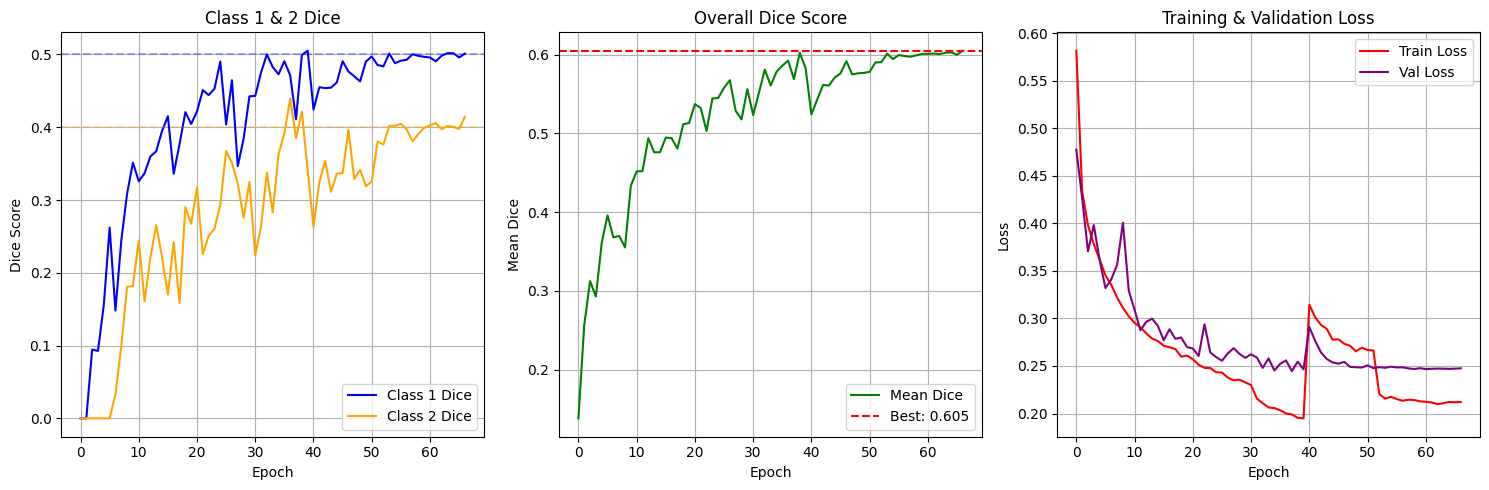


🎉 Training complete!
📁 Check your Google Drive at: /content/drive/MyDrive/Severstal_UNet_Training


In [ ]:
# ============================================================
# CONTINUE TRAINING - FORCE SAVE BEST WEIGHTS
# ============================================================

# 1. IMPORTS
import os
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import cv2
import albumentations as A
from sklearn.model_selection import train_test_split
from google.colab import drive

# 2. MOUNT DRIVE
drive.mount("/content/drive")

# 3. PATHS
DRIVE_OUTPUT_DIR = "/content/drive/MyDrive/Severstal_UNet_Training"
CHECKPOINT_DIR = os.path.join(DRIVE_OUTPUT_DIR, "checkpoints")
RESULTS_DIR = os.path.join(DRIVE_OUTPUT_DIR, "results")
BEST_MODEL_PATH = os.path.join(CHECKPOINT_DIR, "best_model.pth")
LAST_MODEL_PATH = os.path.join(CHECKPOINT_DIR, "last_checkpoint.pth")
HISTORY_PATH = os.path.join(RESULTS_DIR, "training_history.csv")
DATASET_DIR = "/content/severstal"
TRAIN_CSV = os.path.join(DATASET_DIR, "train.csv")
TRAIN_IMAGE_DIR = os.path.join(DATASET_DIR, "train_images")

# 4. CONFIGURATION
NUM_CLASSES = 5
IMAGE_HEIGHT = 256
IMAGE_WIDTH = 512
BATCH_SIZE = 16
NUM_ADDITIONAL_EPOCHS = 15   
LEARNING_RATE = 3e-5  
WEIGHT_DECAY = 2e-4  # Regularization
NUM_WORKERS = 4
VAL_SIZE = 0.20
EARLY_STOPPING_PATIENCE = 20  
SEED = 42
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_amp = (DEVICE.type == "cuda")

print("="*50)
print("DEVICE")
print("="*50)
print(DEVICE)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# 5. SET SEED
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = True
set_seed(SEED)

# 6. LOAD DATASET
df = pd.read_csv(TRAIN_CSV)

def rle_decode(rle, shape=(256, 1600)):
    mask = np.zeros(shape[0] * shape[1], dtype=np.uint8)
    if pd.isna(rle):
        return mask.reshape(shape, order="F")
    values = np.asarray(rle.split(), dtype=np.int64)
    starts = values[0::2] - 1
    lengths = values[1::2]
    ends = starts + lengths
    for start, end in zip(starts, ends):
        mask[start:end] = 1
    return mask.reshape(shape, order="F")

# 7. TRAIN/VAL SPLIT
image_ids = df["ImageId"].unique().tolist()
train_ids, val_ids = train_test_split(
    image_ids, test_size=VAL_SIZE, random_state=SEED, shuffle=True
)
train_ids = list(train_ids)
val_ids = list(val_ids)

# 8. DATASET CLASS
class SteelDefectDataset(Dataset):
    def __init__(self, image_ids, df, image_dir, transform=None):
        self.image_ids = list(image_ids)
        self.df = df
        self.image_dir = image_dir
        self.transform = transform
        self.annotations = {image_id: group for image_id, group in df.groupby("ImageId")}

    def __len__(self):
        return len(self.image_ids)

    def __getitem__(self, idx):
        image_id = self.image_ids[idx]
        image_path = os.path.join(self.image_dir, image_id)
        image = cv2.imread(image_path)
        if image is None:
            raise FileNotFoundError(f"Image not found: {image_path}")
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        mask = np.zeros((256, 1600), dtype=np.uint8)
        if image_id in self.annotations:
            rows = self.annotations[image_id]
            for _, row in rows.iterrows():
                class_id = int(row["ClassId"])
                class_mask = rle_decode(row["EncodedPixels"], shape=(256, 1600))
                mask[class_mask == 1] = class_id

        if self.transform is not None:
            augmented = self.transform(image=image, mask=mask)
            image = augmented["image"]
            mask = augmented["mask"]

        image = cv2.resize(image, (IMAGE_WIDTH, IMAGE_HEIGHT), interpolation=cv2.INTER_LINEAR)
        mask = cv2.resize(mask, (IMAGE_WIDTH, IMAGE_HEIGHT), interpolation=cv2.INTER_NEAREST)

        image = image.astype(np.float32) / 255.0
        image = torch.from_numpy(image).permute(2, 0, 1)
        mask = torch.from_numpy(mask).long()
        return image, mask

# 9. TRANSFORMS 
train_transform = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.2),
    A.RandomBrightnessContrast(brightness_limit=0.15, contrast_limit=0.15, p=0.3),
    A.Affine(scale=(0.95, 1.05), translate_percent=(-0.05, 0.05), rotate=(-5, 5), p=0.3),
])

val_transform = None

# 10. CREATE DATASETS
train_dataset = SteelDefectDataset(
    image_ids=train_ids, df=df, image_dir=TRAIN_IMAGE_DIR, transform=train_transform
)
val_dataset = SteelDefectDataset(
    image_ids=val_ids, df=df, image_dir=TRAIN_IMAGE_DIR, transform=val_transform
)

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=True, persistent_workers=True
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=True, persistent_workers=True
)

# 11. U-NET MODEL
class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )
    def forward(self, x):
        return self.block(x)

class DownBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.pool = nn.MaxPool2d(kernel_size=2)
        self.conv = DoubleConv(in_channels, out_channels)
    def forward(self, x):
        x = self.pool(x)
        x = self.conv(x)
        return x

class UpBlock(nn.Module):
    def __init__(self, in_channels, skip_channels, out_channels):
        super().__init__()
        self.up = nn.ConvTranspose2d(in_channels, in_channels // 2, kernel_size=2, stride=2)
        self.conv = DoubleConv(in_channels // 2 + skip_channels, out_channels)
    def forward(self, x, skip):
        x = self.up(x)
        diff_y = skip.size(2) - x.size(2)
        diff_x = skip.size(3) - x.size(3)
        x = F.pad(x, [diff_x // 2, diff_x - diff_x // 2, diff_y // 2, diff_y - diff_y // 2])
        x = torch.cat([skip, x], dim=1)
        x = self.conv(x)
        return x

class UNet(nn.Module):
    def __init__(self, in_channels=3, num_classes=5, base_channels=32):
        super().__init__()
        self.inc = DoubleConv(in_channels, base_channels)
        self.down1 = DownBlock(base_channels, base_channels * 2)
        self.down2 = DownBlock(base_channels * 2, base_channels * 4)
        self.down3 = DownBlock(base_channels * 4, base_channels * 8)
        self.down4 = DownBlock(base_channels * 8, base_channels * 16)
        self.up1 = UpBlock(base_channels * 16, base_channels * 8, base_channels * 8)
        self.up2 = UpBlock(base_channels * 8, base_channels * 4, base_channels * 4)
        self.up3 = UpBlock(base_channels * 4, base_channels * 2, base_channels * 2)
        self.up4 = UpBlock(base_channels * 2, base_channels, base_channels)
        self.out = nn.Conv2d(base_channels, num_classes, kernel_size=1)
    def forward(self, x):
        x1 = self.inc(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        x4 = self.down3(x3)
        x5 = self.down4(x4)
        x = self.up1(x5, x4)
        x = self.up2(x, x3)
        x = self.up3(x, x2)
        x = self.up4(x, x1)
        return self.out(x)

# 12. LOSS FUNCTIONS 
class MultiClassDiceLoss(nn.Module):
    def __init__(self, num_classes=5, smooth=1e-6, exclude_background=True):
        super().__init__()
        self.num_classes = num_classes
        self.smooth = smooth
        self.exclude_background = exclude_background

    def forward(self, logits, target):
        probs = torch.softmax(logits, dim=1)
        target_one_hot = F.one_hot(target, num_classes=self.num_classes)
        target_one_hot = target_one_hot.permute(0, 3, 1, 2).float()

        if self.exclude_background:
            probs = probs[:, 1:]
            target_one_hot = target_one_hot[:, 1:]

        probs = probs.reshape(probs.size(0), probs.size(1), -1)
        target_one_hot = target_one_hot.reshape(target_one_hot.size(0), target_one_hot.size(1), -1)

        intersection = (probs * target_one_hot).sum(dim=2)
        denominator = probs.sum(dim=2) + target_one_hot.sum(dim=2)
        dice = (2.0 * intersection + self.smooth) / (denominator + self.smooth)

        target_pixels = target_one_hot.sum(dim=2)
        valid = target_pixels > 0
        if valid.any():
            dice = dice[valid]
            return 1.0 - dice.mean()
        return 1.0 - dice.mean()


def calculate_pixel_counts(df):
    pixel_counts = {1: 0, 2: 0, 3: 0, 4: 0}
    for class_id, group in df.groupby("ClassId"):
        total_pixels = 0
        for rle in group["EncodedPixels"]:
            values = np.fromstring(rle, sep=" ", dtype=np.int64)
            lengths = values[1::2]
            total_pixels += lengths.sum()
        pixel_counts[int(class_id)] = total_pixels
    return pixel_counts

pixel_counts = calculate_pixel_counts(df)
freq = np.array([pixel_counts[1], pixel_counts[2], pixel_counts[3], pixel_counts[4]], dtype=np.float64)
max_freq = freq.max()
defect_weights = np.sqrt(max_freq / freq)

defect_weights[0] *= 1.3  #  1
defect_weights[1] *= 1.3  #  2
defect_weights = np.clip(defect_weights, 1.0, 8.0)
defect_weights = defect_weights / defect_weights.mean()
class_weights = np.array([0.25, defect_weights[0], defect_weights[1], defect_weights[2], defect_weights[3]], dtype=np.float32)

ce_weights = torch.tensor(class_weights, dtype=torch.float32).to(DEVICE)
cross_entropy_loss = nn.CrossEntropyLoss(weight=ce_weights)
dice_loss = MultiClassDiceLoss(num_classes=NUM_CLASSES, exclude_background=True)

def combined_loss(logits, target):
    ce = cross_entropy_loss(logits, target)
    dice = dice_loss(logits, target)
    return 0.4 * ce + 0.6 * dice  # CE Dice

# 13. METRICS FUNCTIONS
def update_confusion_matrix(confusion, target, prediction, num_classes):
    target = target.reshape(-1)
    prediction = prediction.reshape(-1)
    valid = (target >= 0) & (target < num_classes)
    target = target[valid]
    prediction = prediction[valid]
    indices = target * num_classes + prediction
    matrix = torch.bincount(indices, minlength=num_classes ** 2)
    matrix = matrix.reshape(num_classes, num_classes)
    confusion += matrix
    return confusion

def calculate_metrics(confusion):
    confusion = confusion.float()
    tp = torch.diag(confusion)
    fp = confusion.sum(dim=0) - tp
    fn = confusion.sum(dim=1) - tp
    dice = (2 * tp) / (2 * tp + fp + fn + 1e-7)
    iou = tp / (tp + fp + fn + 1e-7)
    return dice, iou

# 14. LOAD BEST MODEL
model = UNet(in_channels=3, num_classes=NUM_CLASSES, base_channels=32).to(DEVICE)


last_checkpoint = torch.load(LAST_MODEL_PATH, map_location=DEVICE, weights_only=False)
model.load_state_dict(last_checkpoint["model_state_dict"])
print(f"\n✅ Loaded last checkpoint from epoch {last_checkpoint['epoch']}")
print(f"Current Best Dice: {last_checkpoint['best_dice']:.5f}")

# 15. SETUP OPTIMIZER & SCHEDULER
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="max", factor=0.5, patience=5, min_lr=1e-7
)

if os.path.exists(LAST_MODEL_PATH):
    optimizer.load_state_dict(last_checkpoint["optimizer_state_dict"])
    scheduler.load_state_dict(last_checkpoint["scheduler_state_dict"])
    print(f"Optimizer state loaded")

# 16. PREPARE FOR TRAINING
scaler = torch.amp.GradScaler('cuda') if use_amp else None
START_EPOCH = last_checkpoint["epoch"] + 1
best_dice = last_checkpoint["best_dice"]
epochs_without_improvement = 0


history = {
    "epoch": [], "train_loss": [], "val_loss": [], "mean_dice": [], "mean_iou": [],
    "class1_dice": [], "class2_dice": [], "class3_dice": [], "class4_dice": [],
    "class1_iou": [], "class2_iou": [], "class3_iou": [], "class4_iou": [],
    "learning_rate": []
}
if os.path.exists(HISTORY_PATH):
    old_history = pd.read_csv(HISTORY_PATH)
    for key in history:
        if key in old_history.columns:
            history[key] = old_history[key].tolist()

print(f"\n📊 Loaded {len(history['epoch'])} previous epochs")
print(f"🚀 Resuming from epoch {START_EPOCH}")
print(f"🎯 Target: Improve all classes while maintaining balance")

# 17. TRAINING FUNCTIONS
def train_one_epoch(model, loader, optimizer, device, scaler):
    model.train()
    running_loss = 0.0
    for images, masks in loader:
        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)

        if use_amp:
            with torch.amp.autocast('cuda'):
                logits = model(images)
                loss = combined_loss(logits, masks)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=2.0)  # افزایش حد clipping
            scaler.step(optimizer)
            scaler.update()
        else:
            logits = model(images)
            loss = combined_loss(logits, masks)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=2.0)
            optimizer.step()

        running_loss += loss.item() * images.size(0)
    return running_loss / len(loader.dataset)

@torch.no_grad()
def validate(model, loader, device):
    model.eval()
    running_loss = 0.0
    confusion = torch.zeros(NUM_CLASSES, NUM_CLASSES, dtype=torch.int64, device=device)

    for images, masks in loader:
        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        if use_amp:
            with torch.amp.autocast('cuda'):
                logits = model(images)
                loss = combined_loss(logits, masks)
        else:
            logits = model(images)
            loss = combined_loss(logits, masks)

        running_loss += loss.item() * images.size(0)
        predictions = torch.argmax(logits, dim=1)
        confusion = update_confusion_matrix(confusion, masks, predictions, NUM_CLASSES)

    val_loss = running_loss / len(loader.dataset)
    dice, iou = calculate_metrics(confusion)
    mean_defect_dice = dice[1:].mean().item()
    mean_defect_iou = iou[1:].mean().item()
    return val_loss, dice.cpu().numpy(), iou.cpu().numpy(), mean_defect_dice, mean_defect_iou

# 18. MAIN TRAINING LOOP 
TOTAL_EPOCHS = START_EPOCH + NUM_ADDITIONAL_EPOCHS
print("\n" + "="*50)
print("STARTING CONTINUOUS TRAINING")
print("="*50)
print(f"Epochs: {START_EPOCH} to {TOTAL_EPOCHS-1}")
print(f"Best Dice to beat: {best_dice:.5f}")


best_class1_dice = 0
best_class2_dice = 0

for epoch in range(START_EPOCH, TOTAL_EPOCHS):
    epoch_start = time.time()

    # Train
    train_loss = train_one_epoch(model, train_loader, optimizer, DEVICE, scaler)

    # Validate
    val_loss, class_dice, class_iou, mean_dice, mean_iou = validate(model, val_loader, DEVICE)

    # Update scheduler
    scheduler.step(mean_dice)
    current_lr = optimizer.param_groups[0]["lr"]

    epoch_time = time.time() - epoch_start

    # Save history
    history["epoch"].append(epoch)
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["mean_dice"].append(mean_dice)
    history["mean_iou"].append(mean_iou)
    history["class1_dice"].append(class_dice[1])
    history["class2_dice"].append(class_dice[2])
    history["class3_dice"].append(class_dice[3])
    history["class4_dice"].append(class_dice[4])
    history["class1_iou"].append(class_iou[1])
    history["class2_iou"].append(class_iou[2])
    history["class3_iou"].append(class_iou[3])
    history["class4_iou"].append(class_iou[4])
    history["learning_rate"].append(current_lr)

    pd.DataFrame(history).to_csv(HISTORY_PATH, index=False)

    # Print results
    print("\n" + "="*50)
    print(f"Epoch [{epoch}/{TOTAL_EPOCHS-1}]")
    print("="*50)
    print(f"Train Loss    : {train_loss:.5f}")
    print(f"Val Loss      : {val_loss:.5f}")
    print(f"Mean Dice     : {mean_dice:.5f} (Best: {best_dice:.5f})")
    print(f"Mean IoU      : {mean_iou:.5f}")
    print(f"LR            : {current_lr:.8f}")
    print(f"Time          : {epoch_time:.1f} sec")

    print("\n📊 Class Dice:")
    print(f"  Class 1: {class_dice[1]:.5f}")
    print(f"  Class 2: {class_dice[2]:.5f}")
    print(f"  Class 3: {class_dice[3]:.5f}")
    print(f"  Class 4: {class_dice[4]:.5f}")

    print("\n📊 Class IoU:")
    print(f"  Class 1: {class_iou[1]:.5f}")
    print(f"  Class 2: {class_iou[2]:.5f}")
    print(f"  Class 3: {class_iou[3]:.5f}")
    print(f"  Class 4: {class_iou[4]:.5f}")

    # ============================================================
    # ============================================================

    save_best = False
    reason = ""

    if mean_dice > best_dice:
        save_best = True
        best_dice = mean_dice
        reason = f"Improved overall mean Dice to {mean_dice:.5f}"

    elif class_dice[2] > best_class2_dice + 0.05:
        save_best = True
        best_class2_dice = class_dice[2]
        reason = f"Class 2 improved to {class_dice[2]:.5f} (+{class_dice[2] - best_class2_dice:.3f})"

    elif (class_dice[1] > 0.50 and class_dice[2] > 0.40):
        save_best = True
        reason = f"Both Class 1 ({class_dice[1]:.3f}) and Class 2 ({class_dice[2]:.3f}) are high"

    if save_best:
        torch.save({
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scheduler_state_dict": scheduler.state_dict(),
            "best_dice": best_dice,
            "class1_dice": class_dice[1],
            "class2_dice": class_dice[2],
            "class3_dice": class_dice[3],
            "class4_dice": class_dice[4],
            "class1_iou": class_iou[1],
            "class2_iou": class_iou[2],
            "class3_iou": class_iou[3],
            "class4_iou": class_iou[4],
            "num_classes": NUM_CLASSES,
            "reason": reason
        }, BEST_MODEL_PATH)
        print(f"\n🔥 NEW BEST MODEL SAVED!")
        print(f"   Reason: {reason}")
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1
        print(f"\n⏳ No improvement yet (patience: {epochs_without_improvement}/{EARLY_STOPPING_PATIENCE})")

    torch.save({
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "best_dice": best_dice,
        "epochs_without_improvement": epochs_without_improvement,
        "num_classes": NUM_CLASSES
    }, LAST_MODEL_PATH)
    print("\n💾 Last checkpoint saved.")

    # Early stopping
    if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
        print(f"\n⏹️ Early stopping at epoch {epoch}")
        break

# 19. FINAL EVALUATION
print("\n" + "="*50)
print("FINAL EVALUATION")
print("="*50)

# Load best model
final_model = UNet(in_channels=3, num_classes=NUM_CLASSES, base_channels=32).to(DEVICE)
if os.path.exists(BEST_MODEL_PATH):
    final_checkpoint = torch.load(BEST_MODEL_PATH, map_location=DEVICE, weights_only=False)
    final_model.load_state_dict(final_checkpoint["model_state_dict"])
    print(f"Loaded best model from epoch {final_checkpoint['epoch']}")
    print(f"Best Dice: {final_checkpoint['best_dice']:.5f}")
    if 'reason' in final_checkpoint:
        print(f"Reason: {final_checkpoint['reason']}")
else:
    print("⚠️ No best model found! Loading last checkpoint...")
    final_checkpoint = torch.load(LAST_MODEL_PATH, map_location=DEVICE, weights_only=False)
    final_model.load_state_dict(final_checkpoint["model_state_dict"])

final_model.eval()

final_val_loss, final_class_dice, final_class_iou, final_mean_dice, final_mean_iou = validate(
    final_model, val_loader, DEVICE
)

print(f"\n📊 Final Results:")
print(f"Validation Loss: {final_val_loss:.5f}")
print(f"Mean Defect Dice: {final_mean_dice:.5f}")
print(f"Mean Defect IoU: {final_mean_iou:.5f}")
print("\nPer-class results:")
for cls in range(1, NUM_CLASSES):
    print(f"  Class {cls} | Dice: {final_class_dice[cls]:.5f} | IoU: {final_class_iou[cls]:.5f}")

# Save final metrics
final_metrics = pd.DataFrame({
    "Class": [1, 2, 3, 4],
    "Dice": [final_class_dice[1], final_class_dice[2], final_class_dice[3], final_class_dice[4]],
    "IoU": [final_class_iou[1], final_class_iou[2], final_class_iou[3], final_class_iou[4]]
})
final_metrics.to_csv(os.path.join(RESULTS_DIR, "final_metrics_balanced.csv"), index=False)

print(f"\n✅ Results saved to: {RESULTS_DIR}")

# 20. PLOT RESULTS
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.plot(history["class1_dice"], label='Class 1 Dice', color='blue')
plt.plot(history["class2_dice"], label='Class 2 Dice', color='orange')
plt.axhline(y=0.5, color='blue', linestyle='--', alpha=0.3)
plt.axhline(y=0.4, color='orange', linestyle='--', alpha=0.3)
plt.xlabel('Epoch')
plt.ylabel('Dice Score')
plt.title('Class 1 & 2 Dice')
plt.legend()
plt.grid()

plt.subplot(1, 3, 2)
plt.plot(history["mean_dice"], label='Mean Dice', color='green')
plt.axhline(y=best_dice, color='red', linestyle='--', label=f'Best: {best_dice:.3f}')
plt.xlabel('Epoch')
plt.ylabel('Mean Dice')
plt.title('Overall Dice Score')
plt.legend()
plt.grid()

plt.subplot(1, 3, 3)
plt.plot(history["train_loss"], label='Train Loss', color='red')
plt.plot(history["val_loss"], label='Val Loss', color='purple')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training & Validation Loss')
plt.legend()
plt.grid()

plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "balanced_training_results.png"), dpi=150, bbox_inches="tight")
plt.show()

print("\n🎉 Training complete!")
print(f"📁 Check your Google Drive at: {DRIVE_OUTPUT_DIR}")

In [ ]:

# ============================================================
# SEVERSTAL - CORRECT TEST INFERENCE
# FULL-SIZE MASK + FULL-SIZE COLOR OVERLAY
# ============================================================

!pip install opencv-python

import os
import cv2
import numpy as np
import torch
from tqdm.auto import tqdm


# ============================================================
# 1. PATHS
# ============================================================

TEST_DIR = "/content/severstal/test_images"

BASE_DIR = (
    "/content/drive/MyDrive/"
    "Severstal_UNet_Training/results/test_predictions"
)

MASK_DIR = os.path.join(BASE_DIR, "colored_masks")
OVERLAY_DIR = os.path.join(BASE_DIR, "overlays")

os.makedirs(MASK_DIR, exist_ok=True)
os.makedirs(OVERLAY_DIR, exist_ok=True)


# ============================================================
# 2. MODEL INPUT SIZE
# ============================================================

MODEL_H = 256
MODEL_W = 512


# ============================================================
# 3. CLASS COLORS
# ============================================================

# OpenCV uses BGR
CLASS_COLORS = {
    1: (0, 0, 255),      # Class 1 = RED
    2: (0, 255, 0),      # Class 2 = GREEN
    3: (255, 0, 0),      # Class 3 = BLUE
    4: (0, 255, 255)     # Class 4 = YELLOW
}


# ============================================================
# 4. PREPROCESSING
# ============================================================

def preprocess_for_model(image):
    rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    rgb = cv2.resize(rgb, (MODEL_W, MODEL_H), interpolation=cv2.INTER_LINEAR)
    rgb = rgb.astype(np.float32) / 255.0
    rgb = np.transpose(rgb, (2, 0, 1))
    return torch.from_numpy(rgb).float()


# ============================================================
# 5. CREATE COLORED MASK
# ============================================================

def create_colored_mask(mask):
    h, w = mask.shape
    colored = np.zeros((h, w, 3), dtype=np.uint8)

    for class_id, color in CLASS_COLORS.items():
        colored[mask == class_id] = color

    return colored


# ============================================================
# 6. GET TEST IMAGES
# ============================================================

test_files = sorted([
    f for f in os.listdir(TEST_DIR)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])

print("=" * 70)
print("SEVERSTAL TEST INFERENCE")
print("=" * 70)
print(f"Test images found: {len(test_files)}")
print(f"Model input: {MODEL_W} x {MODEL_H}")
print(f"\nMasks will be saved to:\n{MASK_DIR}")
print(f"\nOverlays will be saved to:\n{OVERLAY_DIR}")


# ============================================================
# 7. PREDICTION
# ============================================================

model.eval()
processed = 0

with torch.no_grad():
    for filename in tqdm(test_files, desc="Predicting Test Images"):
        image_path = os.path.join(TEST_DIR, filename)

        # Read original image
        original = cv2.imread(image_path, cv2.IMREAD_COLOR)

        if original is None:
            print(f"\n⚠️ Cannot read: {filename}")
            continue

        original_h, original_w = original.shape[:2]

        # Preprocess
        tensor = preprocess_for_model(original)
        tensor = tensor.unsqueeze(0).to(DEVICE)

        # U-Net inference
        output = model(tensor)

        # Class prediction
        prediction_small = torch.argmax(
            output, dim=1
        )[0].cpu().numpy().astype(np.uint8)

        # Restore original image dimensions
        # INTER_NEAREST must be used for segmentation masks.
        prediction = cv2.resize(
            prediction_small,
            (original_w, original_h),
            interpolation=cv2.INTER_NEAREST
        )

        # Create colored mask
        colored_mask = create_colored_mask(prediction)

        # Create overlay
        overlay = original.copy()
        defect_pixels = prediction > 0

        if np.any(defect_pixels):
            overlay[defect_pixels] = (
                0.55 * original[defect_pixels].astype(np.float32)
                + 0.45 * colored_mask[defect_pixels].astype(np.float32)
            ).astype(np.uint8)

        base_name = os.path.splitext(filename)[0]

        # Save colored mask
        mask_path = os.path.join(
            MASK_DIR,
            base_name + "_colored_mask.png"
        )
        cv2.imwrite(mask_path, colored_mask)

        # Save full-size overlay
        overlay_path = os.path.join(
            OVERLAY_DIR,
            base_name + "_overlay.jpg"
        )
        cv2.imwrite(
            overlay_path,
            overlay,
            [cv2.IMWRITE_JPEG_QUALITY, 95]
        )

        processed += 1


# ============================================================
# 8. FINAL REPORT
# ============================================================

print("\n" + "=" * 70)
print("✅ TEST INFERENCE COMPLETED")
print("=" * 70)

print(f"Total test images : {len(test_files)}")
print(f"Successfully done : {processed}")
print(f"\nColored masks:\n{MASK_DIR}")
print(f"\nFull-size overlays:\n{OVERLAY_DIR}")

print("\n✅ Original image dimensions were preserved.")
print("✅ Prediction masks were resized with INTER_NEAREST.")
print("✅ Background of the overlay remains the original image.")

